# NSI OneByOne Profile plots

In [19]:
using FileIO
using CairoMakie

## load data

In [20]:
#load scan results 
scan_data = Dict{String, Any}()
#scan_data["profile_eμ"] = FileIO.load("deepcore3y_180926_profile_eμ_441points_psoseed1.jld2")
scan_data["profile_eμ"] = FileIO.load("nsi_scan_posterior_2d_multinode_eμ_05112026_231777_0_profile_eμ_441points_psoseed3.jld2")
#scan_data["profile_eτ"] = FileIO.load("deepcore3y_180926_profile_eτ_441points_psoseed1.jld2")
scan_data["profile_eτ"] = FileIO.load("nsi_scan_posterior_2d_multinode_eτ_05112026_231777_1_profile_eτ_441points_psoseed3.jld2")
#scan_data["profile_μτ"] = FileIO.load("deepcore3y_180926_profile_μτ_441points_psoseed1.jld2")
scan_data["profile_μτ"] = FileIO.load("nsi_scan_posterior_2d_multinode_μτ_06112026_231777_2_profile_μτ_441points_psoseed3.jld2")
#scan_data["profile_ee_μμ"] = FileIO.load("deepcore3y_180926_profile_ee_μμ_51points_psoseed1.jld2")
scan_data["profile_ee_μμ"] = FileIO.load("nsi_scan_posterior_1d_multinode_ee_μμ_05112026_231776_0_profile_ee_μμ_51points_psoseed3.jld2")
#scan_data["profile_ττ_μμ"] = FileIO.load("deepcore3y_180926_profile_ττ_μμ_51points_psoseed1.jld2")
scan_data["profile_ττ_μμ"] = FileIO.load("nsi_scan_posterior_1d_multinode_ττ_μμ_05112026_231776_1_profile_ττ_μμ_51points_psoseed3.jld2")
scan_data["profile_all"] = FileIO.load("deepcore3y_180926_profile_all_200points_psoseed1.jld2")


Dict{String, Any} with 13 entries:
  "objective"     => "posterior"
  "seed_strategy" => "pso"
  "nseeds"        => 1
  "mesh_flat"     => [[0.0, 0.0, 0.15, 0.175, 0.035, 3.14159, 3.14159, 3.14159]…
  "llh"           => [-556.372, -545.617, -548.878, -561.217, -549.367, -546.40…
  "scan_keys"     => (:Δ_eμ, :Δ_τμ, :ε_eμ_abs, :ε_eτ_abs, :ε_μτ_abs, :δ_eμ, :δ_…
  "log_posterior" => [-557.803, -542.782, -548.99, -560.175, -549.103, -544.986…
  "n_grid"        => 200
  "converged"     => Bool[1, 1, 1, 1, 1, 1, 1, 1, 1, 1  …  1, 1, 1, 1, 1, 1, 1,…
  "hypothesis"    => "all"
  "n_iterations"  => [411, 221, 155, 147, 182, 202, 184, 136, 143, 118  …  153,…
  "lbfgs_time"    => [3673.41, 2140.43, 1624.27, 1566.47, 1882.34, 2013.56, 188…
  "fit_params"    => [(atm_flux_delta_spectral_index = -0.0387265, atm_flux_nue…

In [21]:
profiles = [scan_data["profile_eμ"], scan_data["profile_eτ"], scan_data["profile_μτ"], scan_data["profile_ee_μμ"], scan_data["profile_ττ_μμ"], scan_data["profile_all"]]
logp = [profile["log_posterior"] for profile in profiles]
llh = [profile["llh"] for profile in profiles]
hypothesis = [profile["hypothesis"] for profile in profiles]
scan_params = [profile["scan_keys"] for profile in profiles]
flat_grid = [profile["mesh_flat"] for profile in profiles]
fit_params = [profile["fit_params"] for profile in profiles]

6-element Vector{Vector{@NamedTuple{atm_flux_delta_spectral_index::Float64, atm_flux_nuenuebar_sigma::Float64, atm_flux_nuenumu_sigma::Float64, atm_flux_numunumubar_sigma::Float64, atm_flux_updown_sigma::Float64, atm_flux_uphorizonzal_sigma::Float64, deepcore_atm_muon_scale::Float64, deepcore_ice_absorption::Float64, deepcore_ice_scattering::Float64, deepcore_lifetime::Float64, deepcore_opt_eff_headon::Float64, deepcore_opt_eff_lateral::Float64, deepcore_opt_eff_overall::Float64, nc_norm::Float64, nutau_cc_norm::Float64, Δ_eμ::Float64, Δ_τμ::Float64, Δm²₂₁::Float64, Δm²₃₁::Float64, δCP::Float64, δ_eμ::Float64, δ_eτ::Float64, δ_μτ::Float64, ε_eμ_abs::Float64, ε_eτ_abs::Float64, ε_μτ_abs::Float64, θ₁₂::Float64, θ₁₃::Float64, θ₂₃::Float64}}}:
 [(atm_flux_delta_spectral_index = -0.019234841577203343, atm_flux_nuenuebar_sigma = 0.4143902476608998, atm_flux_nuenumu_sigma = -0.2730556964280526, atm_flux_numunumubar_sigma = 0.04994774354759322, atm_flux_updown_sigma = -0.011451472544093271, at

In [22]:
fit_params[1][1].atm_flux_delta_spectral_index

-0.019234841577203343

## CL contour plots

### real valued nsi

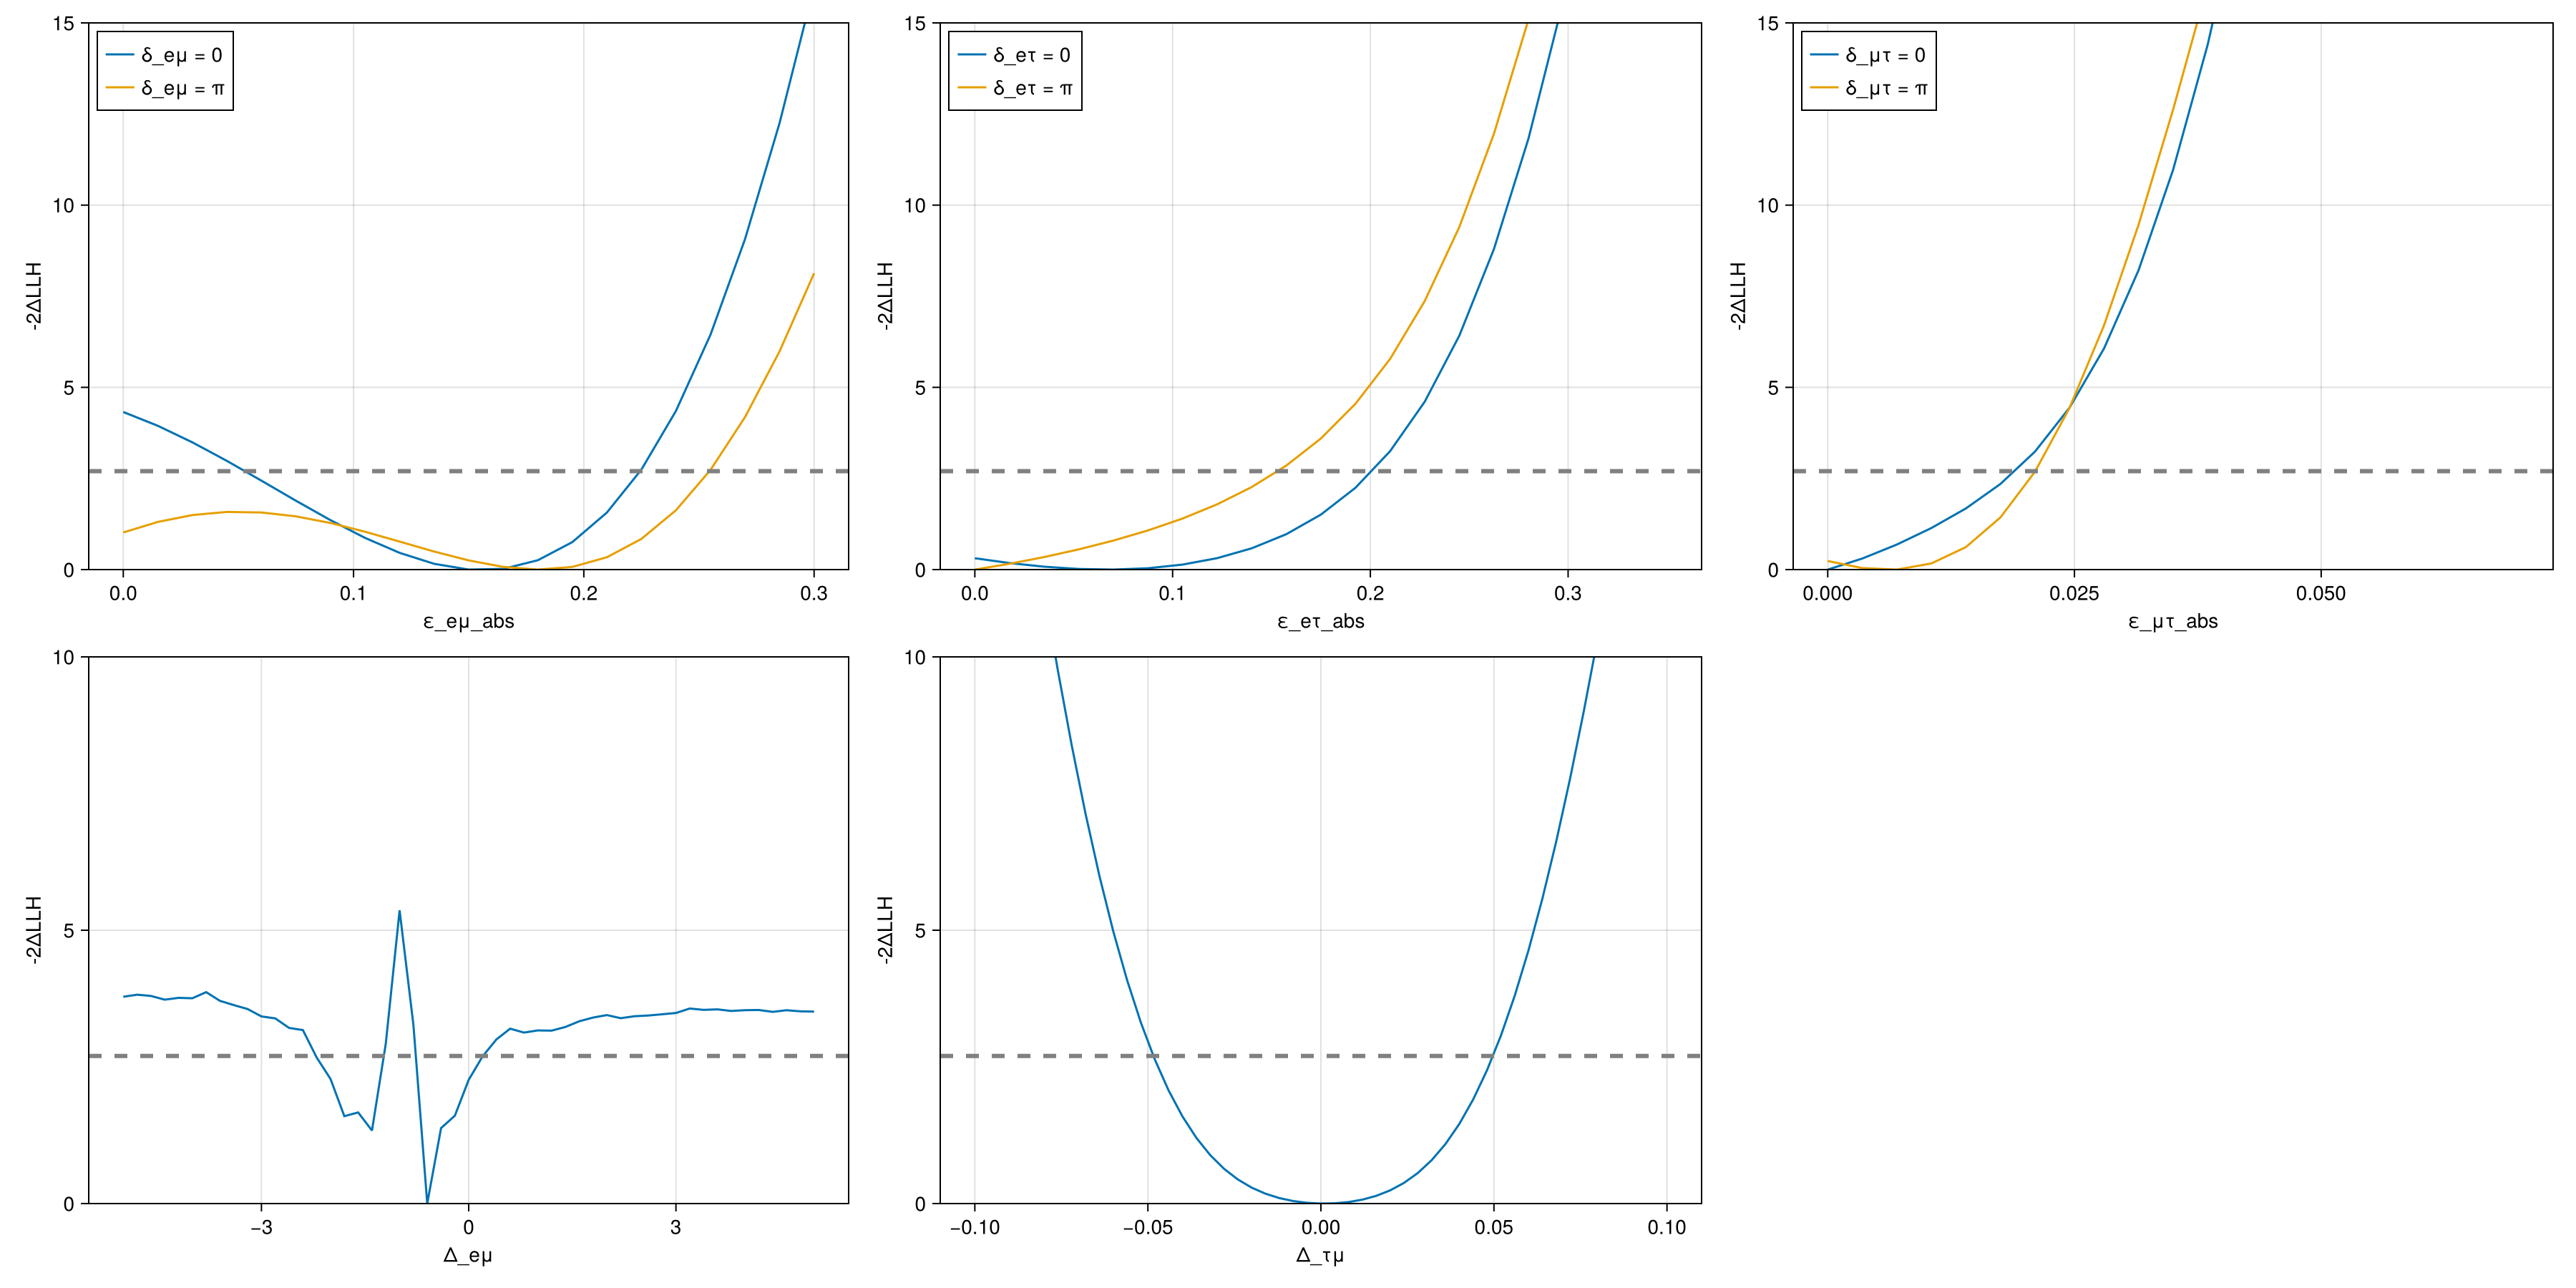

In [23]:
#plot real part of off-diagonal ε_αβ (δ=0, π slices of the 2D profile) for eμ, eτ, μτ,
#plus the genuinely 1D ee_μμ/ττ_μμ profiles

fig = Figure(size=(1800, 900))

for i in 1:3
    n1 = n2 = Int(round(sqrt(length(llh[i]))))
    logp_grid = reshape(logp[i], n1, n2)
    abs_vals = [flat_grid[i][k][1] for k in 1:n1]
    del_vals = [flat_grid[i][(j-1)*n1+1][2] for j in 1:n2]

    j0 = argmin(abs.(del_vals .- 0))
    jπ = argmin(abs.(del_vals .- π))
    llh0 = logp_grid[:, j0]
    llhπ = logp_grid[:, jπ]

    ax = Axis(fig[1,i], limits=(nothing, (0,15)), xlabel=string(scan_params[i][1]), ylabel="-2ΔLLH")
    lines!(ax, abs_vals, -2*(llh0 .- maximum(llh0)), label="$(scan_params[i][2]) = 0")
    lines!(ax, abs_vals, -2*(llhπ .- maximum(llhπ)), label="$(scan_params[i][2]) = π")
    hlines!(ax, [2.7], linestyle=:dash, color=:gray, linewidth=3)
    axislegend(ax, position=:lt)
end

for (col, i) in enumerate((4, 5))
    x = [pt[1] for pt in flat_grid[i]]
    order = sortperm(x)
    x = x[order]
    ΔLLH = -2 .* (logp[i][order] .- maximum(logp[i]))

    ax = Axis(fig[2,col], xlabel=string(scan_params[i][1]), ylabel="-2ΔLLH", limits=(nothing, (0,10)))
    lines!(ax, x, ΔLLH)
    hlines!(ax, [2.7], linestyle=:dash, color=:gray, linewidth=3)
end

fig

In [24]:
profile_Δ_eμ = FileIO.load("../../../nsi_analysis/Scan_data/nsi_OneByOne_deepcore_100pts_03072026_profile_Δ_eμ.jld2", "result")
profile_Δ_τμ = FileIO.load("../../../nsi_analysis/Scan_data/nsi_OneByOne_deepcore_100pts_03072026_profile_Δ_τμ.jld2", "result")


┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\.julia\packages\JLD2\qcxKY\src\data\reconstructing_datatypes.jl:588
┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\.julia\packages\JLD2\qcxKY\src\data\reconstructing_datatypes.jl:588


Reconstruct@NewtrinosResult(Any[(Δ_τμ = [-0.1, -0.09797979797979799, -0.09595959595959597, -0.09393939393939395, -0.09191919191919193, -0.08989898989898991, -0.08787878787878789, -0.08585858585858586, -0.08383838383838384, -0.08181818181818182, -0.0797979797979798, -0.07777777777777778, -0.07575757575757576, -0.07373737373737374, -0.07171717171717172, -0.0696969696969697, -0.06767676767676767, -0.06565656565656566, -0.06363636363636363, -0.061616161616161624, -0.0595959595959596, -0.05757575757575758, -0.05555555555555556, -0.05353535353535354, -0.051515151515151514, -0.049494949494949494, -0.047474747474747475, -0.04545454545454546, -0.043434343434343436, -0.04141414141414142, -0.0393939393939394, -0.03737373737373738, -0.035353535353535345, -0.03333333333333334, -0.03131313131313132, -0.0292929292929293, -0.027272727272727268, -0.02525252525252525, -0.023232323232323243, -0.02121212121212121, -0.01919191919191919, -0.01717171717171717, -0.015151515151515152, -0.013131313131313133, -0

### complex valued nsi

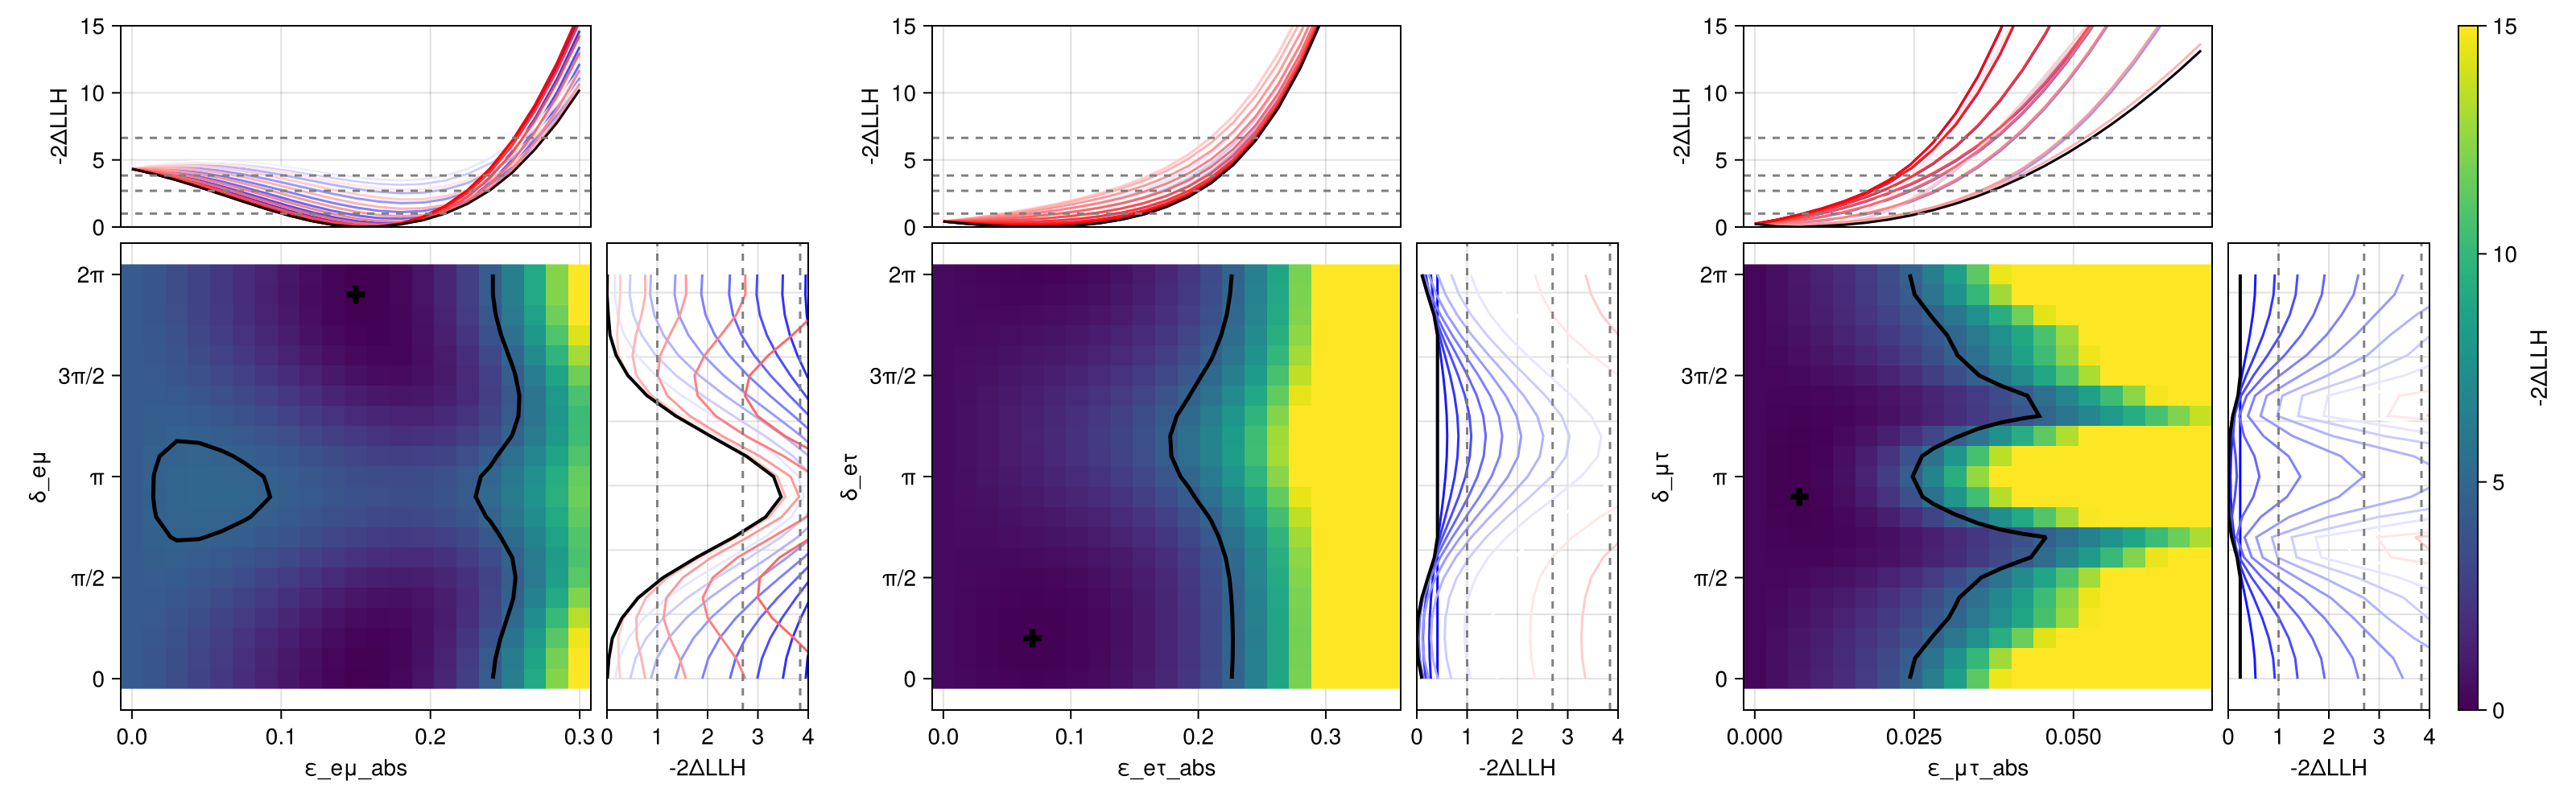

In [25]:
fig = Figure(size = (1600, 500))
cmap = cgrad([:blue, :white, :red])
for i in 1:3
    n1 = n2 = Int(round(sqrt(length(llh[i]))))
    logp_grid = reshape(logp[i], n1, n2)
    abs_vals = [flat_grid[i][k][1] for k in 1:n1]
    del_vals = [flat_grid[i][(j-1)*n1+1][2] for j in 1:n2]

    abs_label = string(scan_params[i][1])
    del_label = string(scan_params[i][2])

    bf_idx = argmax(logp[i])
    bf_abs, bf_del = flat_grid[i][bf_idx]

    # eigenes 2x2-Sub-Layout für diesen Parameter
    gl = fig[1, i] = GridLayout()
    global_max = maximum(logp_grid)

    # 1D Profile for |ε_αβ|
    llh1D_ε = [maximum(logp_grid[k, :]) for k in 1:n1]

    ax_top = Axis(gl[1, 1], ylabel = "-2ΔLLH", limits = (nothing, (0, 15)))
    for j in 1:n2
        t = (j - (n2+1)/2) / ((n2-1)/2)
        t_norm = (t + 1) / 2
        y = logp_grid[:, j]
        ΔLLH = y .- global_max
        lines!(ax_top, abs_vals, -2*ΔLLH, color=cmap[t_norm])
    end
    lines!(ax_top, abs_vals, -2*(llh1D_ε .- maximum(llh1D_ε)), color=:black)
    hlines!(ax_top, [1, 2.7, 3.84, 6.64], linestyle = :dash, color = :gray, linewidth = 1.5)

    # 2D profile
    ax_main = Axis(gl[2, 1], xlabel = abs_label, ylabel = del_label,
                   yticks = ([0, π/2, π, 3π/2, 2π], ["0", "π/2", "π", "3π/2", "2π"]))
    levels = [0, 4.61]
    heatmap!(ax_main, abs_vals, del_vals, -2 .* (logp_grid .- global_max), alpha = 1, colorrange = (0, 15))
    contour!(ax_main, abs_vals, del_vals, -2 .* (logp_grid .- global_max), levels = levels, linewidth = 2.5, color=:black)
    scatter!(ax_main, [bf_abs], [bf_del], color = :black, marker = :cross, markersize = 15)

    # 1D Profile for δ_αβ
    llh1D_δ = [maximum(logp_grid[:, k]) for k in 1:n2]

    ax_right = Axis(gl[2, 2], xlabel = "-2ΔLLH", limits = ((0, 4), nothing))

    for k in 1:n1
        t = (k - (n1+1)/2) / ((n1-1)/2)
        t_norm = (t + 1) / 2
        y = logp_grid[k, :]
        ΔLLH = y .- global_max
        lines!(ax_right, -2*ΔLLH, del_vals, color=cmap[t_norm])
    end
    lines!(ax_right, -2*(llh1D_δ .- maximum(llh1D_δ)), del_vals, color=:black, linewidth=2)
    vlines!(ax_right, [1, 2.7, 3.84, 6.64], linestyle = :dash, color = :gray, linewidth = 1.5)

    #ax layout:
    linkxaxes!(ax_top, ax_main)     # oben teilt sich |ε|-Achse mit Hauptpanel
    linkyaxes!(ax_main, ax_right)   # rechts teilt sich δ-Achse mit Hauptpanel

    hidexdecorations!(ax_top, grid = false)
    hideydecorations!(ax_right, grid = false)

    rowsize!(gl, 1, Relative(0.3))
    colsize!(gl, 2, Relative(0.3))
    rowgap!(gl, 10)
    colgap!(gl, 10)
end

Colorbar(fig[1, 4], limits = (0, 15), colormap = :viridis, label = "-2ΔLLH")

fig

## prior pull plot

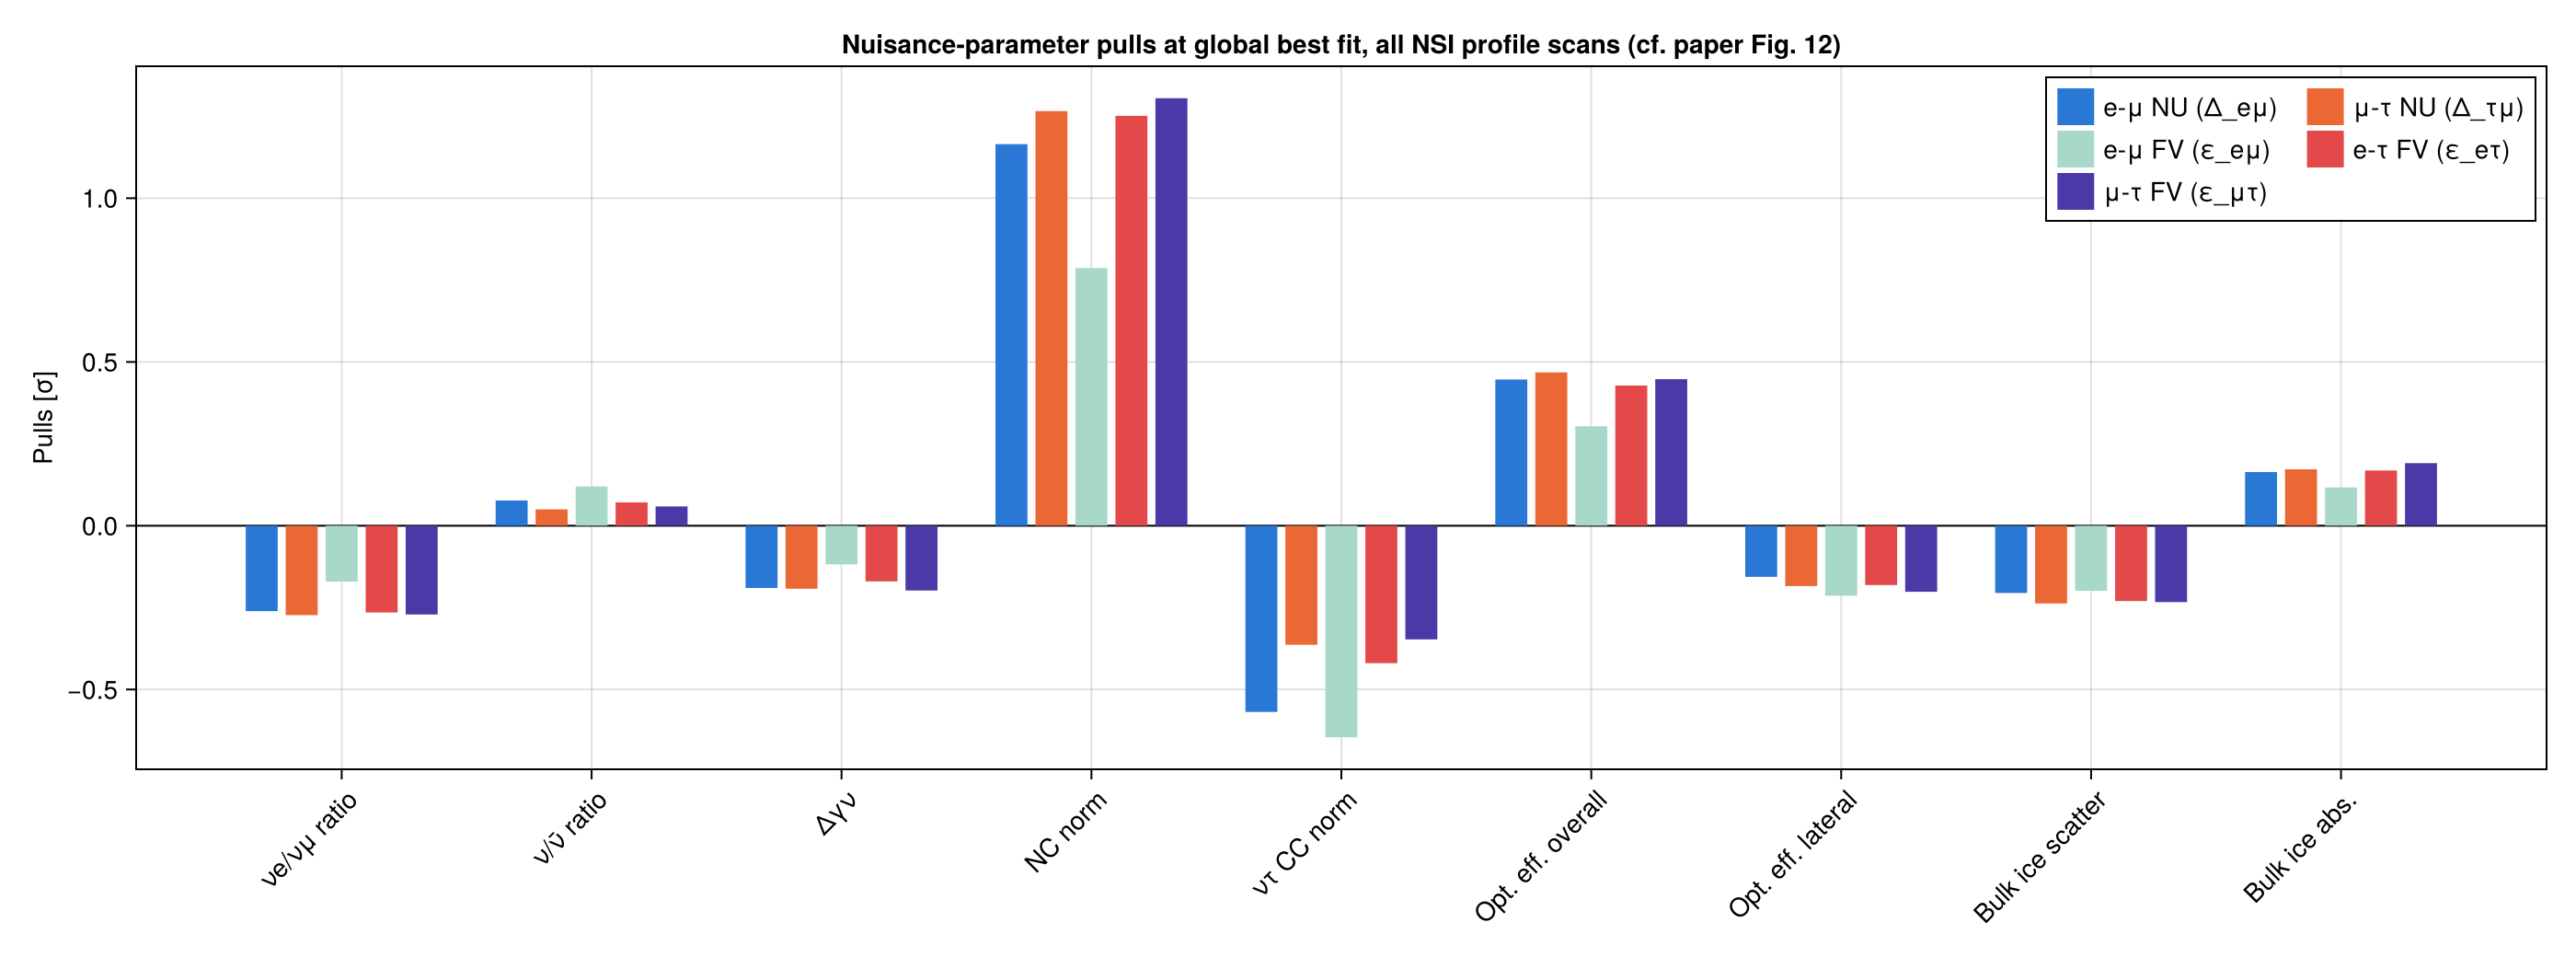

In [26]:
# Nuisance-parameter pull plot (cf. paper Fig. 12), across all NSI profile scans.
# Pulls are computed in units of each parameter's own prior σ, evaluated at the GLOBAL
# best-fit point of each scan (matching the paper's methodology), for every nuisance
# parameter that has a Gaussian/Truncated-Normal prior (flat-prior params like θ₂₃,
# Δm²₃₁, deepcore_lifetime, deepcore_atm_muon_scale, deepcore_opt_eff_headon are excluded,
# same as the paper's own Fig. 12 -- it only shows params "to which Gaussian priors are
# associated"). M_A^CCQE / M_A^res are omitted entirely: the public data release doesn't
# carry the GENIE coefficients needed to model them, so they don't exist in this fit at all.

pull_params = [
    (:atm_flux_nuenumu_sigma,        "νe/νμ ratio",       0.0, 1.0),
    (:atm_flux_numunumubar_sigma,    "ν/ν̄ ratio",         0.0, 1.0),
    (:atm_flux_delta_spectral_index, "Δγν",               0.0, 0.1),
    (:nc_norm,                       "NC norm",           1.0, 0.2),
    (:nutau_cc_norm,                 "ντ CC norm",        1.0, 0.2),
    (:deepcore_opt_eff_overall,      "Opt. eff. overall", 1.0, 0.1),
    (:deepcore_opt_eff_lateral,      "Opt. eff. lateral", 0.0, 1.0),
    (:deepcore_ice_scattering,       "Bulk ice scatter",  1.0, 0.1),
    (:deepcore_ice_absorption,       "Bulk ice abs.",     1.0, 0.1),
]

function best_fit_pulls(i)
    chi2 = -2.0 .* logp[i]
    idx = argmin(chi2)
    fp = fit_params[i][idx]
    [(fp[key] - mu) / sigma for (key, label, mu, sigma) in pull_params]
end

hypotheses = [
    ("e-μ NU (Δ_eμ)", 4, "#2a78d6"),
    ("μ-τ NU (Δ_τμ)", 5, "#eb6834"),
    ("e-μ FV (ε_eμ)", 1, "#a8d8c9"),
    ("e-τ FV (ε_eτ)", 2, "#e34948"),
    ("μ-τ FV (ε_μτ)", 3, "#4a3aa7"),
]

pulls = [best_fit_pulls(h[2]) for h in hypotheses]

labels = [p[2] for p in pull_params]
n = length(labels)
ngroups = length(hypotheses)
w = 0.8 / ngroups

fig_pulls = Figure(size = (1400, 520))
ax = Axis(fig_pulls[1, 1],
    xticks = (1:n, labels), xticklabelrotation = π/4,
    ylabel = "Pulls [σ]",
    title = "Nuisance-parameter pulls at global best fit, all NSI profile scans (cf. paper Fig. 12)")

hlines!(ax, [0], color = :black, linewidth = 1)
for (gi, (label, i, color)) in enumerate(hypotheses)
    offset = (gi - (ngroups+1)/2) * w
    barplot!(ax, (1:n) .+ offset, pulls[gi], width = w, color = color, label = label)
end
axislegend(ax, position = :rt, nbanks = 2)

fig_pulls

## "all" hypothesis (8D Sobol scan)

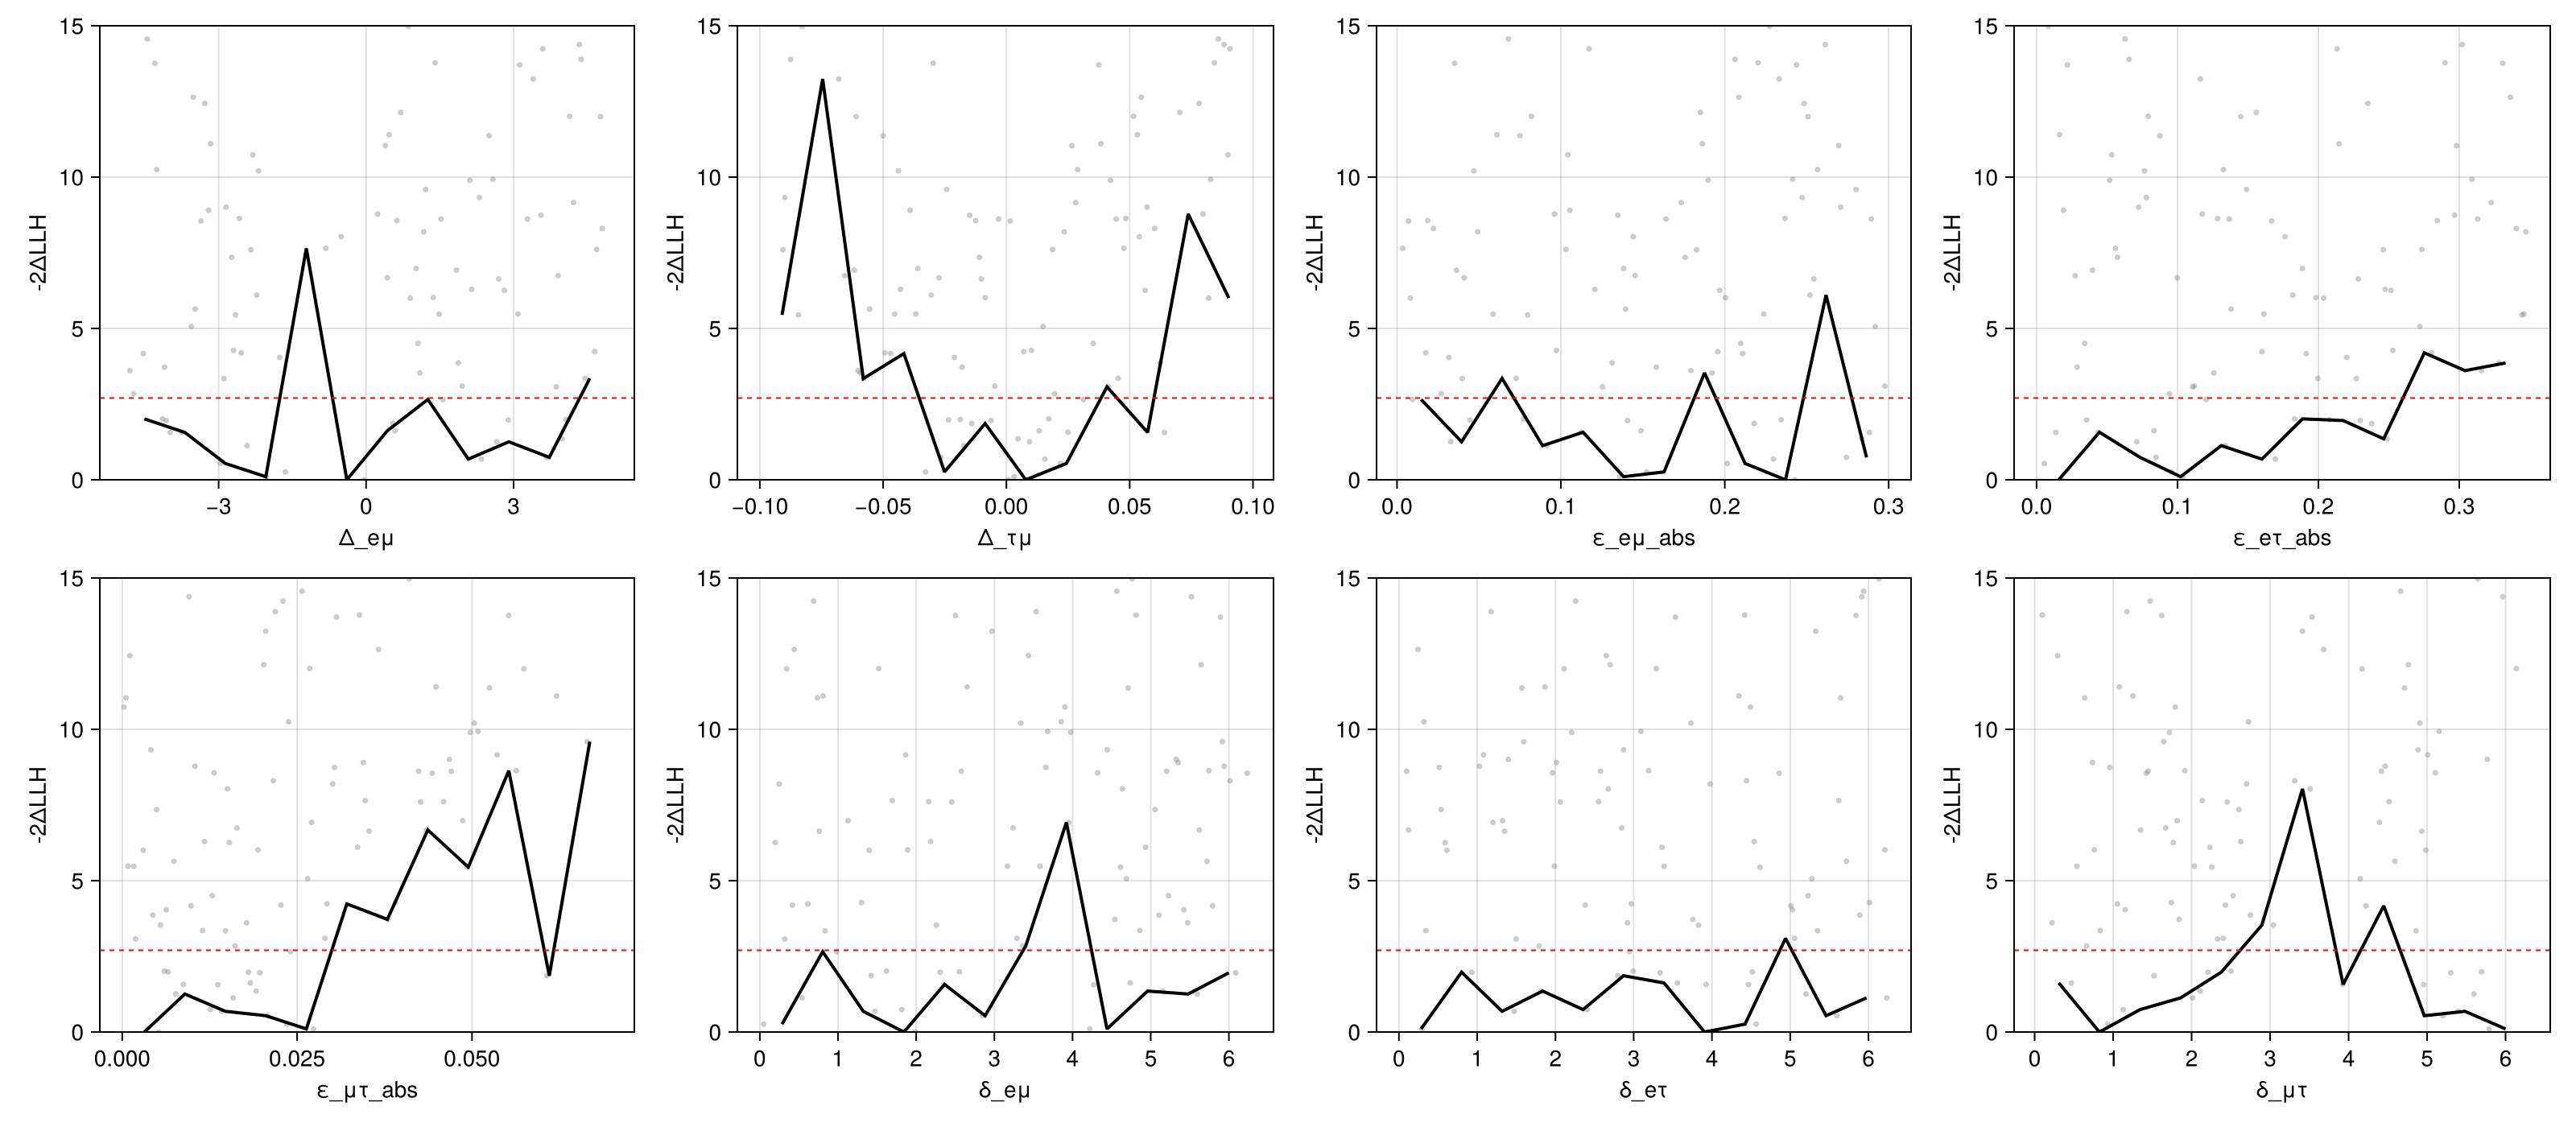

In [27]:
# Approximate 1D profile per NSI parameter: the "all" hypothesis is an 8D Sobol point
# cloud (not a factorial grid), so a true profile isn't available -- instead, for each
# parameter we bin the unstructured samples along that axis and take the minimum -2ΔLLH
# within each bin, as an approximate profile likelihood.

i_all = 6
params_all = scan_params[i_all]
x_all = [ [pt[k] for pt in flat_grid[i_all]] for k in eachindex(params_all) ]
ΔLLH_all = -2 .* (logp[i_all] .- maximum(logp[i_all]))

nbins = 12

fig_all1d = Figure(size = (1600, 700))
for (k, pname) in enumerate(params_all)
    row, col = divrem(k-1, 4) .+ (1, 1)
    ax = Axis(fig_all1d[row, col], xlabel = string(pname), ylabel = "-2ΔLLH", limits = (nothing, (0, 15)))

    xs = x_all[k]
    scatter!(ax, xs, ΔLLH_all, color = (:gray, 0.4), markersize = 5)

    edges = range(minimum(xs), maximum(xs), length = nbins+1)
    centers = [(edges[b] + edges[b+1]) / 2 for b in 1:nbins]
    bin_min = fill(NaN, nbins)
    for b in 1:nbins
        lo, hi = edges[b], edges[b+1]
        in_bin = b == nbins ? (xs .>= lo) .& (xs .<= hi) : (xs .>= lo) .& (xs .< hi)
        if any(in_bin)
            bin_min[b] = minimum(ΔLLH_all[in_bin])
        end
    end
    valid = .!isnan.(bin_min)
    lines!(ax, centers[valid], bin_min[valid], color = :black, linewidth = 2)

    hlines!(ax, [2.7], linestyle = :dash, color = :red, linewidth = 1)
end

fig_all1d

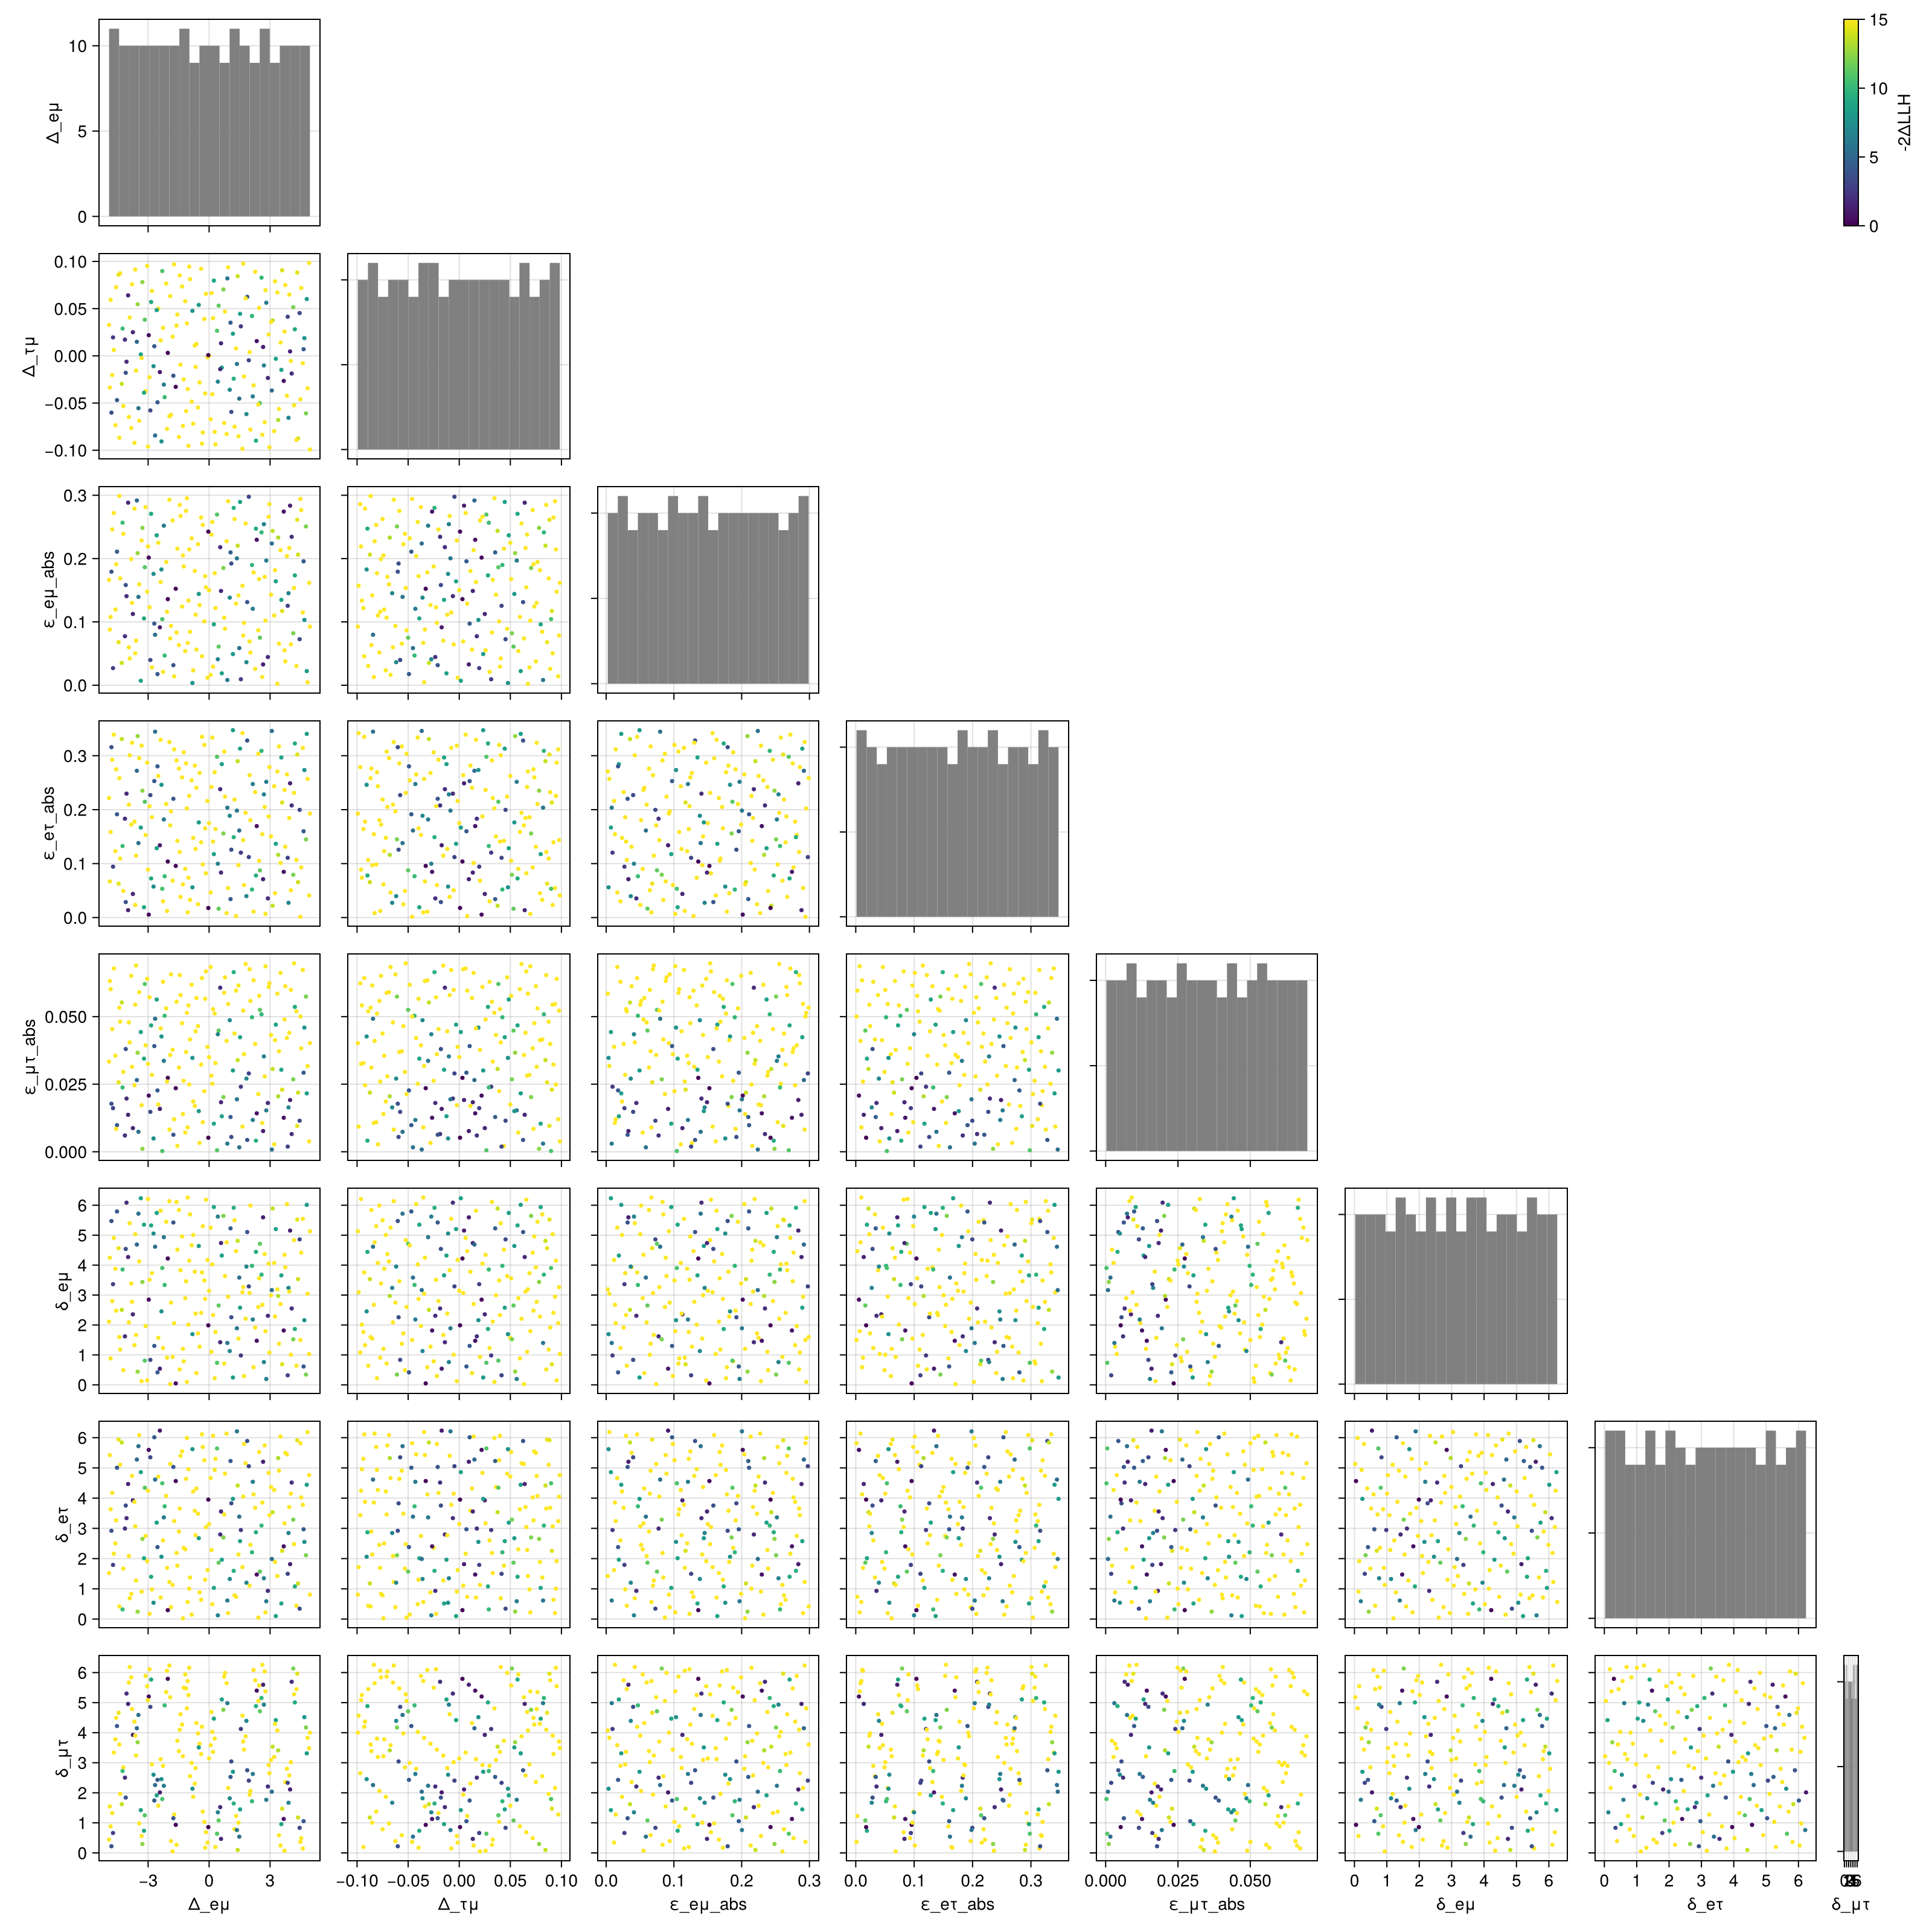

In [28]:
# Corner plot: lower-triangle grid of pairwise Sobol-sample scatters, colored by -2ΔLLH.
# Not a smoothed contour (200 points in 8D is sparse per 2D panel) -- meant as a quick
# overview of pairwise structure/degeneracies in the "all" hypothesis scan.

n_params = length(params_all)

fig_corner = Figure(size = (1600, 1600))
axes_grid = Matrix{Any}(fill(nothing, n_params, n_params))

crange = (0, 15)
for row in 1:n_params, col in 1:row
    ax = Axis(fig_corner[row, col])
    axes_grid[row, col] = ax

    if row == col
        hist!(ax, x_all[row], color = :gray, bins = 20)
        ax.ylabel = row == 1 ? string(params_all[row]) : ""
    else
        scatter!(ax, x_all[col], x_all[row], color = ΔLLH_all, colormap = :viridis,
                 colorrange = crange, markersize = 5)
    end

    if row == n_params
        ax.xlabel = string(params_all[col])
    else
        hidexdecorations!(ax, grid = false, ticks = false)
    end
    if col == 1 && row != col
        ax.ylabel = string(params_all[row])
    elseif col != 1
        hideydecorations!(ax, grid = false, ticks = false)
    end
end

Colorbar(fig_corner[1, n_params], limits = crange, colormap = :viridis, label = "-2ΔLLH")

fig_corner

## compare to lbfgs profiles

In [29]:
lbfgs_profile_Δ_eμ = FileIO.load("../../../nsi_analysis/Scan_data/nsi_OneByOne_deepcore_100pts_03072026_profile_Δ_eμ.jld2", "result")
lbfgs_profile_Δ_τμ = FileIO.load("../../../nsi_analysis/Scan_data/nsi_OneByOne_deepcore_100pts_03072026_profile_Δ_τμ.jld2", "result")
lbfgs_profile_ε_eμ_abs = FileIO.load("../../../nsi_analysis/Scan_data/nsi_OneByOne_deepcore_100pts_03072026_profile_ε_eμ_abs.jld2", "result")
lbfgs_profile_ε_eτ_abs = FileIO.load("../../../nsi_analysis/Scan_data/nsi_OneByOne_deepcore_100pts_03072026_profile_ε_eτ_abs.jld2", "result")
lbfgs_profile_ε_μτ_abs = FileIO.load("../../../nsi_analysis/Scan_data/nsi_OneByOne_deepcore_100pts_03072026_profile_ε_μτ_abs.jld2", "result")


lbfgs_profile_Δ_eμ = FileIO.load("../../../nsi_analysis/Scan_data/nsi_1by1_deltaemu_deepcore_100pts_21072026_194126_profile_Δ_eμ.jld2", "result")
lbfgs_profile_Δ_τμ = FileIO.load("../../../nsi_analysis/Scan_data/nsi_1by1_deltataumu_deepcore_100pts_21072026_194127_profile_Δ_τμ.jld2", "result")
lbfgs_profile_ε_eμ_abs = FileIO.load("../../../nsi_analysis/Scan_data/nsi_1by1_epsilonemu_deepcore_31x31pts_21072026_194125_profile_ε_eμ_abs.jld2", "result")
lbfgs_profile_ε_eτ_abs = FileIO.load("../../../nsi_analysis/Scan_data/nsi_1by1_epsilonetau_deepcore_31x31pts_21072026_194123_profile_ε_eτ_abs.jld2", "result")
lbfgs_profile_ε_μτ_abs = FileIO.load("../../../nsi_analysis/Scan_data/nsi_1by1_epsilonmutau_deepcore_31x31pts_21072026_194122_profile_ε_μτ_abs.jld2", "result")


┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\.julia\packages\JLD2\qcxKY\src\data\reconstructing_datatypes.jl:588
┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\.julia\packages\JLD2\qcxKY\src\data\reconstructing_datatypes.jl:588
┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\.julia\packages\JLD2\qcxKY\src\data\reconstructing_datatypes.jl:588
┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\.julia\packages\JLD2\qcxKY\src\data\reconstructing_datatypes.jl:588
┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\.julia\packages\JLD2\qcxKY\src\data\reconstructing_datatypes.jl:588
┌ Warning: type Newtrinos.NewtrinosResult does not exist in workspace; reconstructing
└ @ JLD2 C:\Users\David\

Reconstruct@NewtrinosResult(Any[(ε_μτ_abs = [0.0, 0.0023333333333333335, 0.004666666666666667, 0.007000000000000001, 0.009333333333333334, 0.011666666666666667, 0.014000000000000002, 0.016333333333333335, 0.018666666666666668, 0.021, 0.023333333333333334, 0.025666666666666667, 0.028000000000000004, 0.030333333333333337, 0.03266666666666667, 0.035, 0.037333333333333336, 0.03966666666666667, 0.042, 0.044333333333333336, 0.04666666666666667, 0.049, 0.051333333333333335, 0.053666666666666675, 0.05600000000000001, 0.05833333333333334, 0.060666666666666674, 0.06300000000000001, 0.06533333333333334, 0.06766666666666668, 0.07], δ_μτ = [0.0, 0.20943951023931953, 0.41887902047863906, 0.6283185307179586, 0.8377580409572781, 1.0471975511965976, 1.2566370614359172, 1.4660765716752369, 1.6755160819145563, 1.8849555921538759, 2.0943951023931953, 2.3038346126325147, 2.5132741228718345, 2.7227136331111543, 2.9321531433504737, 3.141592653589793, 3.3510321638291125, 3.560471674068432, 3.7699111843077517,

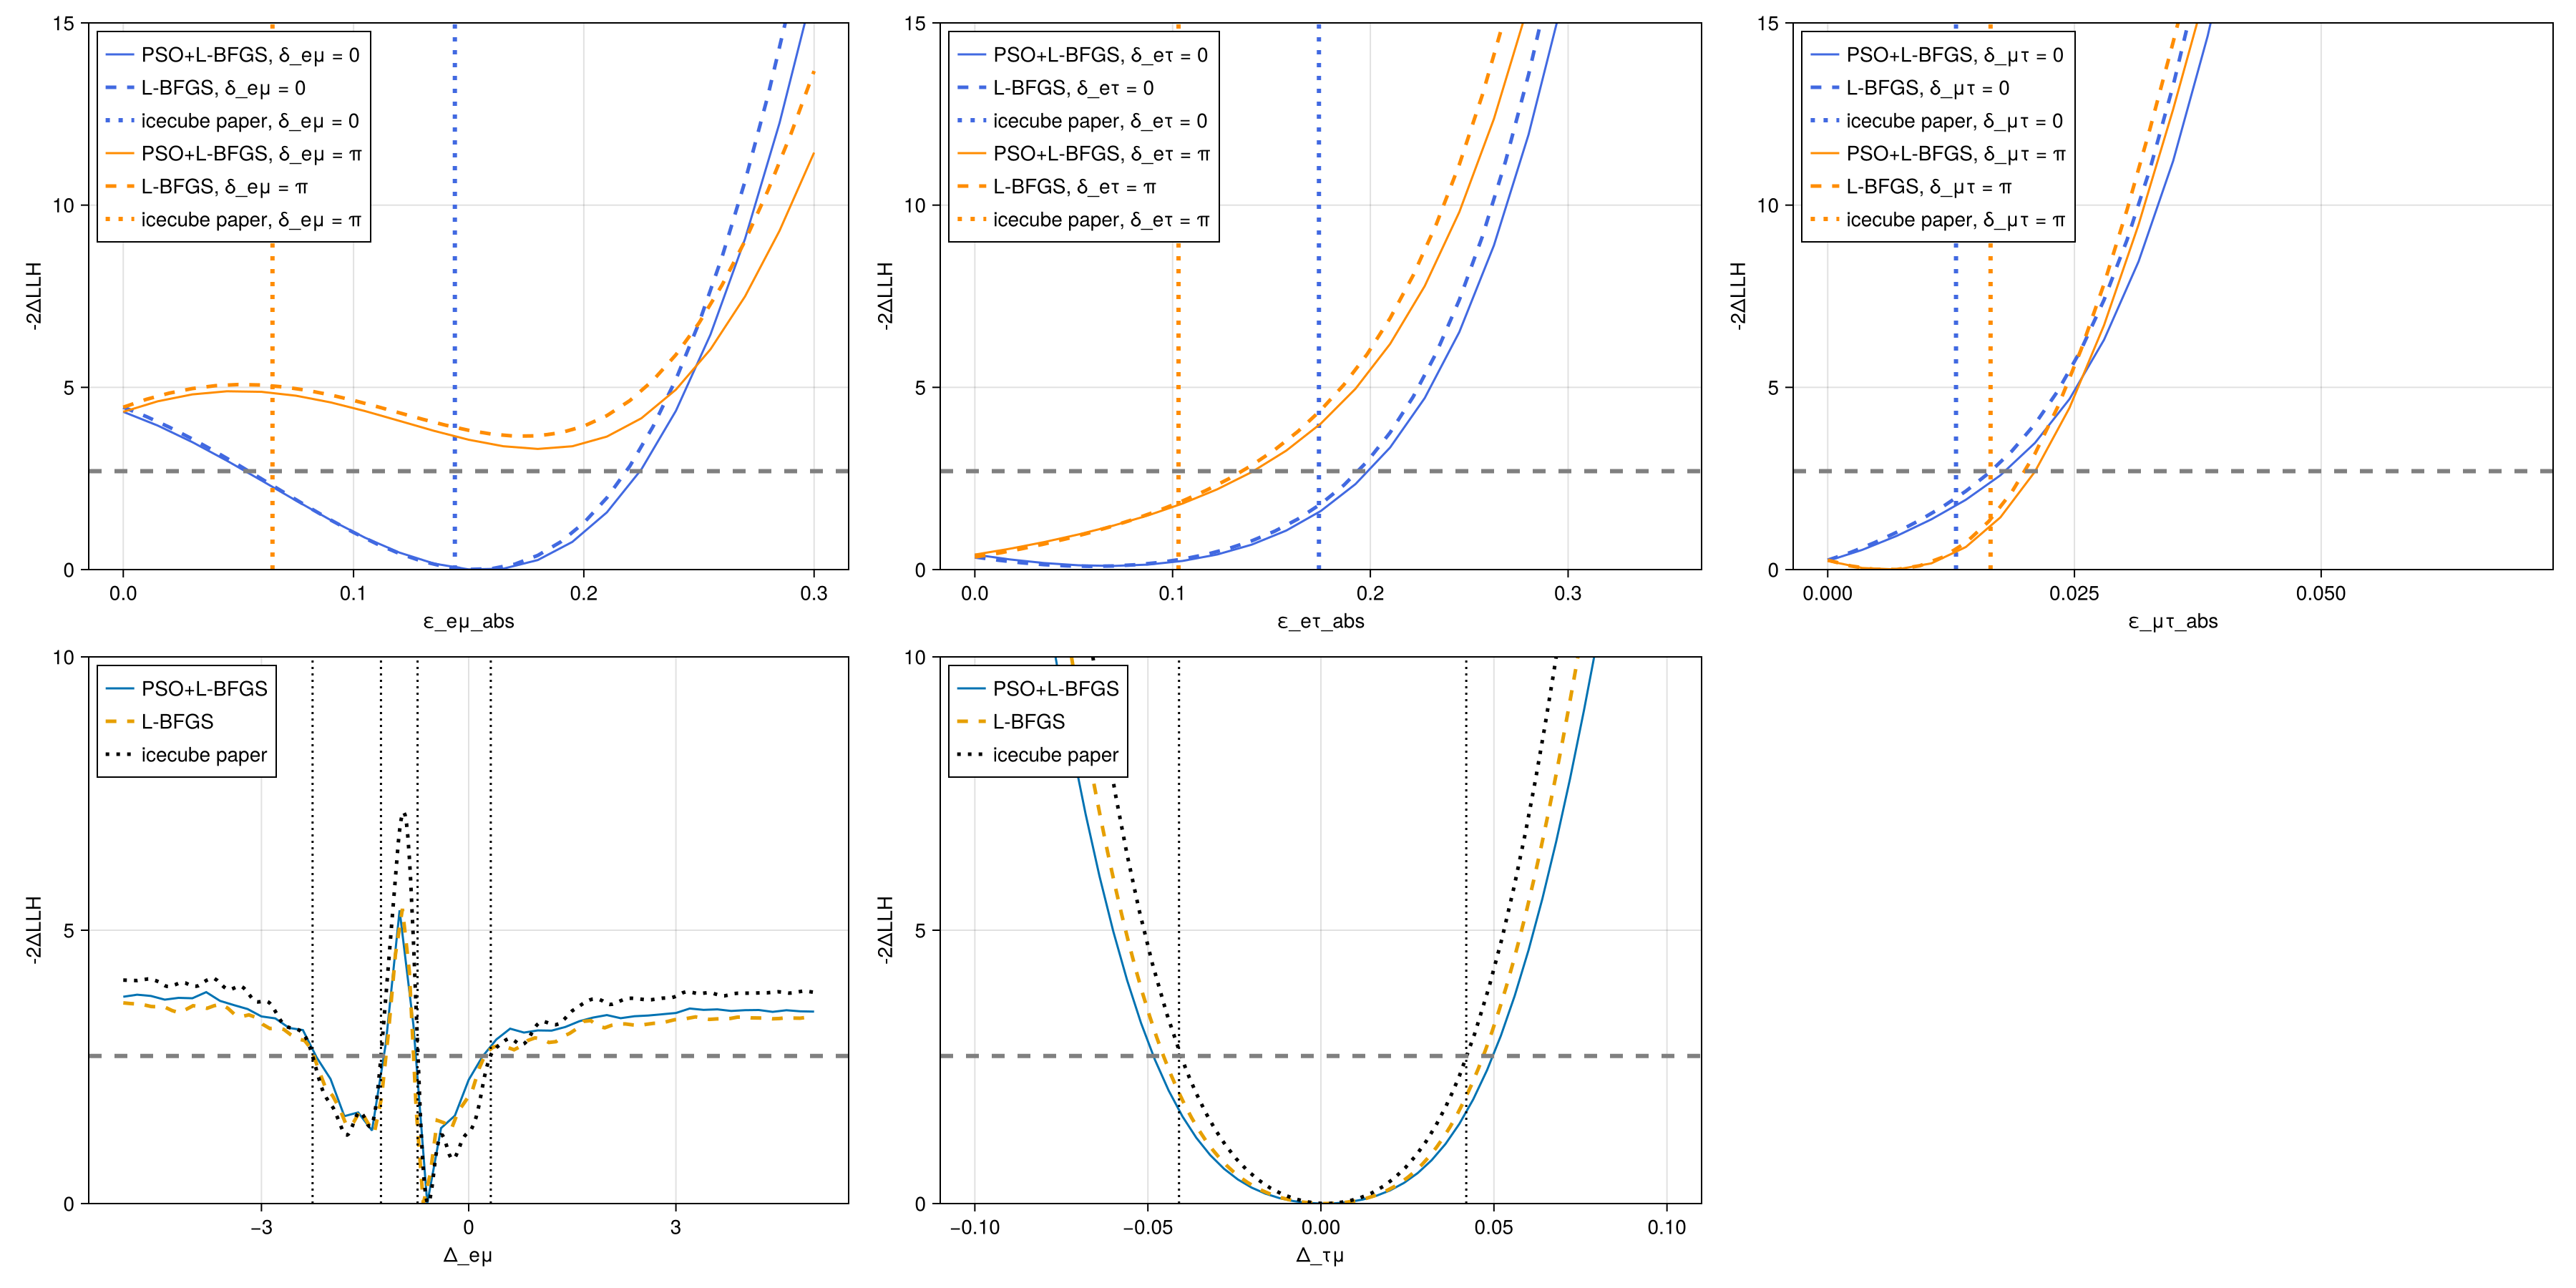

In [30]:
# Comparison PSO+L-BFGS (profiles above, solid) vs pure L-BFGS (dashed) vs IceCube paper (dotted): real-valued NSI.
# Same layout as the "real valued nsi" plot: δ=0, π slices for eμ, eτ, μτ plus the 1D ee_μμ / ττ_μμ profiles.
# Each method is referenced to its own global best log-posterior (shape comparison).
# The paper (PRD 104, 072006) enters as its 90% CL limits (vertical dotted lines): for eμ, eτ, μτ the δ=0 limit
# (upper) and the δ=π limit (|lower|) in the colour of the corresponding slice; for the diagonal panels the
# allowed-interval edges of Table V. The paper's Fig. 3 profile curve is also drawn in the bottom row.
# The curves of its Fig. 4 are δ-projected profiles (not δ=0/π slices), so they appear in the complex-valued
# comparison below instead.

# digitized IceCube paper curves and limits (extracted from the vector graphics of the PDF)
include("icecube_paper_digitized.jl")

# the lbfgs files are reconstructed JLD2 structs: field 1 = Any[axes, values, meta]
function lbfgs_unpack(r)
    p = getfield(r, 1)
    axs, vals = p[1], p[2]
    n1 = length(first(axs))
    lp = reshape(collect(Float64, vals.log_posterior), n1, :)
    return axs, lp
end
finite_max(x) = maximum(filter(isfinite, x))

# PSO index in `profiles` => lbfgs result (ε_αβ_abs with δ, or Δ_eμ / Δ_τμ for ee_μμ / ττ_μμ)
lbfgs_res = Dict(1 => lbfgs_profile_ε_eμ_abs, 2 => lbfgs_profile_ε_eτ_abs, 3 => lbfgs_profile_ε_μτ_abs,
                 4 => lbfgs_profile_Δ_eμ, 5 => lbfgs_profile_Δ_τμ)
paper_lims = Dict(1 => icecube_paper_limits.eμ, 2 => icecube_paper_limits.eτ, 3 => icecube_paper_limits.μτ)

fig = Figure(size=(1800, 900))

for i in 1:3
    n1 = n2 = Int(round(sqrt(length(llh[i]))))
    logp_grid = reshape(logp[i], n1, n2)
    abs_vals = [flat_grid[i][k][1] for k in 1:n1]
    del_vals = [flat_grid[i][(j-1)*n1+1][2] for j in 1:n2]

    axs_l, lp_l = lbfgs_unpack(lbfgs_res[i])
    abs_l, del_l = axs_l[1], axs_l[2]

    max_pso = finite_max(logp_grid)
    max_l   = finite_max(lp_l)

    ax = Axis(fig[1,i], limits=(nothing, (0,15)), xlabel=string(scan_params[i][1]), ylabel="-2ΔLLH")
    for (δ0, δlabel, color, plim) in ((0, "0", :royalblue, paper_lims[i].upper), (π, "π", :darkorange, abs(paper_lims[i].lower)))
        j  = argmin(abs.(del_vals .- δ0))
        jl = argmin(abs.(del_l .- δ0))
        lines!(ax, abs_vals, -2*(logp_grid[:, j] .- max_pso), color=color, label="PSO+L-BFGS, $(scan_params[i][2]) = $δlabel")
        lines!(ax, abs_l, -2*(lp_l[:, jl] .- max_l), color=color, linestyle=:dash, linewidth=2.5, label="L-BFGS, $(scan_params[i][2]) = $δlabel")
        vlines!(ax, [plim], color=color, linestyle=:dot, linewidth=3, label="icecube paper, $(scan_params[i][2]) = $δlabel")
    end
    hlines!(ax, [2.7], linestyle=:dash, color=:gray, linewidth=3)
    axislegend(ax, position=:lt)
end

for (col, i) in enumerate((4, 5))
    x = [pt[1] for pt in flat_grid[i]]
    order = sortperm(x)
    x = x[order]
    axs_l, lp_l = lbfgs_unpack(lbfgs_res[i])
    x_l = axs_l[1]
    paper = i == 4 ? icecube_paper.nu_eμ : icecube_paper.nu_τμ
    paper_edges = i == 4 ? icecube_paper_limits.nu_eμ : icecube_paper_limits.nu_τμ

    ax = Axis(fig[2,col], xlabel=string(scan_params[i][1]), ylabel="-2ΔLLH", limits=(nothing, (0,10)))
    lines!(ax, x, -2 .* (logp[i][order] .- finite_max(logp[i])), label="PSO+L-BFGS")
    lines!(ax, x_l, -2 .* (vec(lp_l) .- finite_max(lp_l)), linestyle=:dash, linewidth=2.5, label="L-BFGS")
    lines!(ax, paper.x, paper.y, color=:black, linestyle=:dot, linewidth=2.5, label="icecube paper")
    vlines!(ax, collect(Iterators.flatten(paper_edges)), color=:black, linestyle=:dot, linewidth=1.5)
    hlines!(ax, [2.7], linestyle=:dash, color=:gray, linewidth=3)
    axislegend(ax, position=:lt)
end

fig

ε_eμ_abs: max logp PSO+L-BFGS - L-BFGS = -0.34832919637233317
ε_eτ_abs: max logp PSO+L-BFGS - L-BFGS = -0.2526389470469894
ε_μτ_abs: max logp PSO+L-BFGS - L-BFGS = -0.2955166397874791


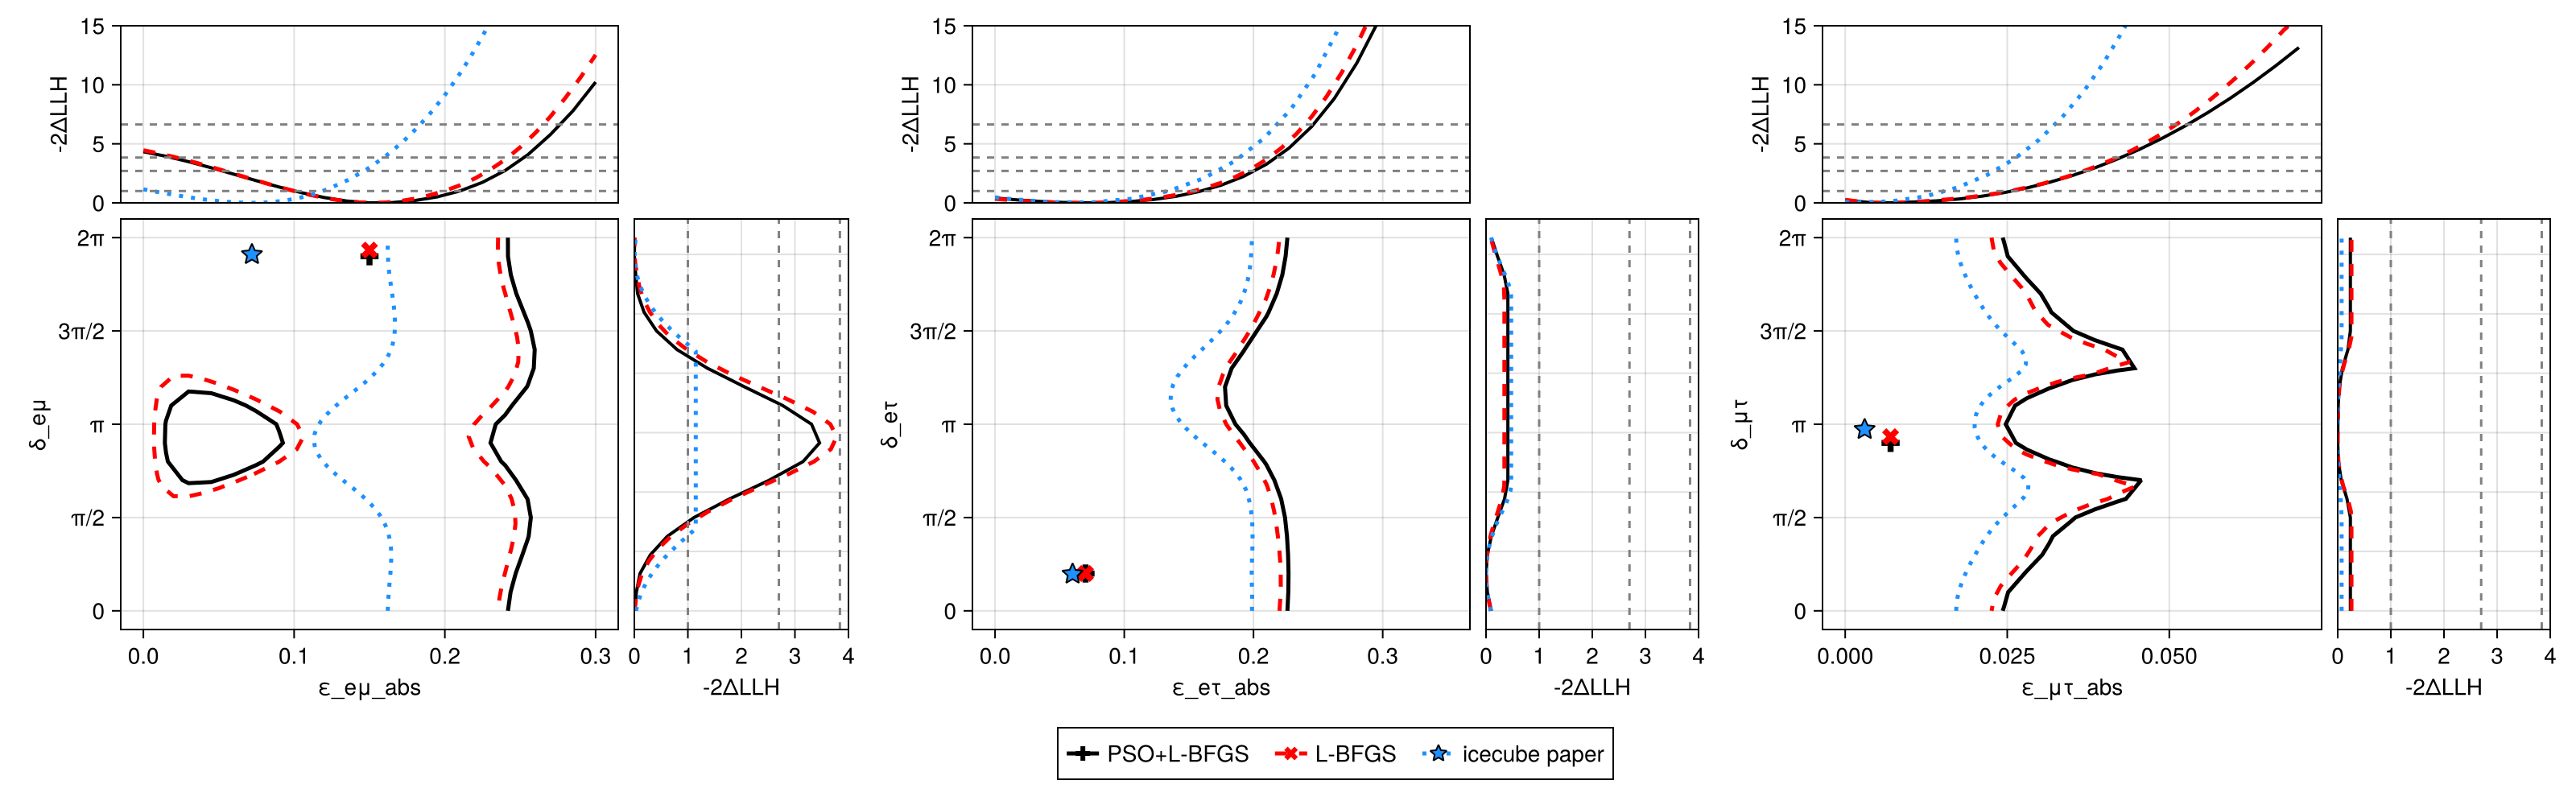

In [33]:
# Comparison PSO+L-BFGS vs pure L-BFGS vs IceCube paper: complex valued NSI (same layout as the "complex valued nsi" plot).
# The L-BFGS scans are full 31x31 (|ε|, δ) grids, so the 2D panel overlays the 90% CL (-2ΔLLH = 4.61)
# contours of the methods; the 1D profiles (top: |ε|, right: δ) compare them directly.
# Each of our methods is referenced to its own global best log-posterior (shape comparison); the gap between
# the two maxima is printed. The IceCube paper curves (PRD 104, 072006, Fig. 4, observed) are the digitized
# projections in icecube_paper_digitized.jl; its best-fit points are from Table IV. Uses lbfgs_unpack /
# finite_max / lbfgs_res / icecube_paper from the previous cell.

paper_keys = Dict(1 => (top = icecube_paper.top_eμ, cont = icecube_paper.cont_eμ, right = icecube_paper.right_eμ),
                  2 => (top = icecube_paper.top_eτ, cont = icecube_paper.cont_eτ, right = icecube_paper.right_eτ),
                  3 => (top = icecube_paper.top_μτ, cont = icecube_paper.cont_μτ, right = icecube_paper.right_μτ))
# paper best fits (Table IV): (|ε|, δ [rad])
paper_bf = Dict(1 => (0.072, deg2rad(343.7)), 2 => (0.060, deg2rad(35.5)), 3 => (0.0030, deg2rad(175.0)))
paper_color = :dodgerblue

fig = Figure(size = (1600, 500))
for i in 1:3
    n1 = n2 = Int(round(sqrt(length(llh[i]))))
    logp_grid = reshape(logp[i], n1, n2)
    abs_vals = [flat_grid[i][k][1] for k in 1:n1]
    del_vals = [flat_grid[i][(j-1)*n1+1][2] for j in 1:n2]
    abs_label = string(scan_params[i][1])
    del_label = string(scan_params[i][2])

    axs_l, lp_l = lbfgs_unpack(lbfgs_res[i])
    abs_l, del_l = axs_l[1], axs_l[2]
    paper = paper_keys[i]

    max_pso = finite_max(logp_grid)
    max_l   = finite_max(lp_l)
    println(scan_params[i][1], ": max logp PSO+L-BFGS - L-BFGS = ", max_pso - max_l)
    Δ_pso = -2 .* (logp_grid .- max_pso)
    Δ_l   = -2 .* (lp_l .- max_l)
    Δ_l_c = map(x -> isfinite(x) ? x : 100.0, Δ_l)   # failed fits -> far outside any contour

    bf_idx = argmax(logp[i])
    bf_abs, bf_del = flat_grid[i][bf_idx]
    bf_l = argmin(Δ_l_c)
    bf_abs_l, bf_del_l = abs_l[bf_l[1]], del_l[bf_l[2]]

    gl = fig[1, i] = GridLayout()

    # 1D profile for |ε_αβ| (δ profiled out)
    prof_ε_pso = [minimum(Δ_pso[k, :]) for k in 1:n1]
    prof_ε_l   = [minimum(Δ_l_c[k, :]) for k in eachindex(abs_l)]

    ax_top = Axis(gl[1, 1], ylabel = "-2ΔLLH", limits = (nothing, (0, 15)))
    lines!(ax_top, abs_vals, prof_ε_pso, color=:black, linewidth=2)
    lines!(ax_top, abs_l, prof_ε_l, color=:red, linestyle=:dash, linewidth=2.5)
    lines!(ax_top, paper.top.x, paper.top.y, color=paper_color, linestyle=:dot, linewidth=2.5)
    hlines!(ax_top, [1, 2.7, 3.84, 6.64], linestyle = :dash, color = :gray, linewidth = 1.5)

    # 2D profile: 4.61 contours of the methods
    ax_main = Axis(gl[2, 1], xlabel = abs_label, ylabel = del_label,
                   yticks = ([0, π/2, π, 3π/2, 2π], ["0", "π/2", "π", "3π/2", "2π"]))
    contour!(ax_main, abs_vals, del_vals, Δ_pso, levels = [4.61], linewidth = 2.5, color=:black)
    contour!(ax_main, abs_l, del_l, Δ_l_c, levels = [4.61], linewidth = 2.5, color=:red, linestyle=:dash)
    lines!(ax_main, paper.cont.x, paper.cont.y, color=paper_color, linestyle=:dot, linewidth=2.5)
    scatter!(ax_main, [bf_abs], [bf_del], color = :black, marker = :cross, markersize = 15)
    scatter!(ax_main, [bf_abs_l], [bf_del_l], color = :red, marker = :xcross, markersize = 15)
    scatter!(ax_main, [paper_bf[i][1]], [paper_bf[i][2]], color = paper_color, marker = :star5, markersize = 15,
             strokecolor = :black, strokewidth = 1)

    # 1D profile for δ_αβ (|ε| profiled out)
    prof_δ_pso = [minimum(Δ_pso[:, k]) for k in 1:n2]
    prof_δ_l   = [minimum(Δ_l_c[:, k]) for k in eachindex(del_l)]

    ax_right = Axis(gl[2, 2], xlabel = "-2ΔLLH", limits = ((0, 4), nothing))
    lines!(ax_right, prof_δ_pso, del_vals, color=:black, linewidth=2)
    lines!(ax_right, prof_δ_l, del_l, color=:red, linestyle=:dash, linewidth=2.5)
    lines!(ax_right, paper.right.x, paper.right.y, color=paper_color, linestyle=:dot, linewidth=2.5)
    vlines!(ax_right, [1, 2.7, 3.84, 6.64], linestyle = :dash, color = :gray, linewidth = 1.5)

    linkxaxes!(ax_top, ax_main)
    linkyaxes!(ax_main, ax_right)
    hidexdecorations!(ax_top, grid = false)
    hideydecorations!(ax_right, grid = false)

    rowsize!(gl, 1, Relative(0.3))
    colsize!(gl, 2, Relative(0.3))
    rowgap!(gl, 10)
    colgap!(gl, 10)
end

Legend(fig[2, 1:3],
       [[LineElement(color=:black, linewidth=2.5), MarkerElement(color=:black, marker=:cross, markersize=12)],
        [LineElement(color=:red, linestyle=:dash, linewidth=2.5), MarkerElement(color=:red, marker=:xcross, markersize=12)],
        [LineElement(color=paper_color, linestyle=:dot, linewidth=2.5),
         MarkerElement(color=paper_color, marker=:star5, markersize=12, strokecolor=:black, strokewidth=1)]],
       ["PSO+L-BFGS", "L-BFGS", "icecube paper"],
       orientation = :horizontal, tellheight = true)

fig

In [32]:
# Rough goodness of fit at the best-fit point of each scan: Poisson deviance D = -2(llh - llh_saturated),
# p = survival function of χ²(ndof), ndof = n_bins - n_free. Rough because the Gaussian-prior nuisance parameters
# constrain the fit only partially (n_free overcounts), but the DeepCore bins are well populated (~320 events/bin
# on average), so the χ² approximation of the deviance is reasonable. Uses lbfgs_res from the real-valued
# comparison cell.
# Checked against nsi/nsi_scan.jl: `llh` is logdensityof(likelihood, mode), i.e. the pure Poisson likelihood of the
# observed counts (no priors); the scanned NSI parameters are fixed by the grid; free per fit are θ₂₃, Δm²₃₁ (2),
# atm. flux (6), detector (7), nc/ντ norm (2) = 17 nuisance parameters.
# The scans must be on the 3y sample (data.csv below): it is the only one consistent with the stored llh values
# (llh <= llh_sat = -475.9 for 3y; the 8y sample has llh_sat = -624.1, below every stored llh).
using Distributions

# observed counts: data.csv has one row per bin (8 E x 8 cosθ x 2 PID = 128 bins)
data_csv = "../../src/experiments/icecube/deepcore_3y_highstats_sample_b/data.csv"
rows_csv = readlines(data_csv)
col = findfirst(==("count"), split(rows_csv[1], ","))
counts = [parse(Float64, split(l, ",")[col]) for l in rows_csv[2:end]]
n_bins = length(counts)
llh_sat = sum(logpdf.(Poisson.(counts), counts))      # saturated model: expectation = observation in every bin

n_nuis = 17
println("n_bins = $n_bins, N_events = $(Int(sum(counts))), llh_sat = $(round(llh_sat, digits=1))")

# llh_v, logp_v: flattened per grid point; d_nsi: number of NSI parameters free at the best-fit point
function gof(method, name, llh_v, logp_v, d_nsi)
    lp = map(x -> isfinite(x) ? x : -Inf, logp_v)
    ib = argmax(lp)                                    # best fit (posterior)
    D = -2 * (llh_v[ib] - llh_sat)
    ndof = n_bins - n_nuis - d_nsi
    (; method, name, χ² = round(D, digits=1), ndof, χ²_per_dof = round(D/ndof, digits=2), p = round(ccdf(Chisq(ndof), D), digits=3))
end

gof_rows = []
for (i, nm) in zip(1:5, ("eμ", "eτ", "μτ", "ee_μμ", "ττ_μμ"))
    d = i <= 3 ? 2 : 1
    push!(gof_rows, gof("PSO+L-BFGS", nm, llh[i], logp[i], d))
    vals_l = getfield(lbfgs_res[i], 1)[2]
    push!(gof_rows, gof("L-BFGS", nm, vec(collect(Float64, vals_l.llh)), vec(collect(Float64, vals_l.log_posterior)), d))
end
foreach(println, gof_rows)

n_bins = 128, N_events = 40902, llh_sat = -475.9
(method = "PSO+L-BFGS", name = "eμ", χ² = 123.9, ndof = 109, χ²_per_dof = 1.14, p = 0.157)
(method = "L-BFGS", name = "eμ", χ² = 123.7, ndof = 109, χ²_per_dof = 1.13, p = 0.159)
(method = "PSO+L-BFGS", name = "eτ", χ² = 126.9, ndof = 109, χ²_per_dof = 1.16, p = 0.116)
(method = "L-BFGS", name = "eτ", χ² = 126.8, ndof = 109, χ²_per_dof = 1.16, p = 0.117)
(method = "PSO+L-BFGS", name = "μτ", χ² = 126.7, ndof = 109, χ²_per_dof = 1.16, p = 0.118)
(method = "L-BFGS", name = "μτ", χ² = 126.5, ndof = 109, χ²_per_dof = 1.16, p = 0.121)
(method = "PSO+L-BFGS", name = "ee_μμ", χ² = 125.1, ndof = 110, χ²_per_dof = 1.14, p = 0.154)
(method = "L-BFGS", name = "ee_μμ", χ² = 125.2, ndof = 110, χ²_per_dof = 1.14, p = 0.152)
(method = "PSO+L-BFGS", name = "ττ_μμ", χ² = 127.3, ndof = 110, χ²_per_dof = 1.16, p = 0.124)
(method = "L-BFGS", name = "ττ_μμ", χ² = 127.1, ndof = 110, χ²_per_dof = 1.16, p = 0.126)
